In [9]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
#from langchain_community.document_loaders import PyPDFLoader 
# # for image + table+ text kind of. data use --> unstructured.io libraries
from pypdf import PdfReader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
#from langchain_community.vectorstores import Chroma
from langchain_chroma import Chroma
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from pydantic import BaseModel
load_dotenv()

True

In [10]:
# step 1 load the document:
pdf_reader = PdfReader("./documents/evs_oil_price_shock.pdf")

text = ""
for page in pdf_reader.pages:
    text += page.extract_text() + "\n"

print(text[:500])


# step 2 split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=100)
docs = [Document(page_content=text)]

chunks = text_splitter.split_documents(docs)

print(len(chunks))

Will EVs Dampen the Oil Price
 Shock?
Electric Vehicles, Oil Demand Destruction, and the Future of Energy Price
 Volatility
 Version 1.0   |   April 2026
 Technical Reference Document

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 2
Table of Contents
3
Executive Summary
 4
1. Introduction
  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  . 4
1.1 Scope and Methodology
 5
2. Oil 
51


In [11]:
# lets intilize our embedding model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# step 3.1 : intilize your storage system 
vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
)


# step 3.2 : add documents to your storage system. (chunk --> vectors)

vectorstore.add_documents(chunks)

['7e81c45c-be37-41c6-ad38-21f5edacf21c',
 'd546bf13-1a76-48bf-ac5e-5a4ac25a2c3c',
 '93d56f28-60f8-4172-a0a5-a2618f096391',
 'cc5dc0a9-5a8a-4140-81ed-45b5794f1c0f',
 '7c6417ab-1603-4fca-b720-dc381359ab70',
 '6260c6aa-cec0-4154-a4dc-3fecce37315d',
 '4be0e3e8-88f9-4282-9946-4b9da8776ca0',
 '8025a140-2d3d-488c-bc15-18d3cfde4b60',
 'aaf98f16-942b-421e-9438-a2a775a1720c',
 '3614b97e-8a63-4dea-9865-22ed4373ab2c',
 '31401b4b-0475-4546-93c9-ceeb21180a29',
 '2a4824f4-25b3-4613-b774-18d8ec3d74d5',
 'bb19988e-271c-4124-9a44-b89ad9c9b032',
 'cb38371e-08c7-43bf-89b0-45639b280f07',
 '22691135-9194-4c30-8b0f-a36efb45c38e',
 '55ccf55e-72a8-4559-8f06-7c2e1f353802',
 'afcbea81-995e-4a4d-a117-0ae4f74b8908',
 'b55236ca-09cf-483f-8f15-2d603dc598e2',
 '22cb2421-8471-4bed-a9ca-fbd99dcc4788',
 'eeaaf356-6c6c-47f4-ba05-4dfd6a224e5d',
 '60f15a2e-ad54-4c02-b4c7-db23a9d6f041',
 '75c68ca7-b207-4239-abe5-90c39c682c1a',
 'b26b00be-8122-4a8e-8296-08b8a05ac587',
 'a76ccbb2-e88a-4a1c-a5ed-a2cac7d694c4',
 'dcf7ddc0-fdc6-

In [12]:
# step 4 : retrieval

retriever = vectorstore.as_retriever( search_kwargs={"k": 2})

In [13]:
# step 1 : Define your state
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: list[Document]
    context: str | None
    generation: str
    needs_retrieval: bool # this is new for case of conditional rag


llm = ChatOpenAI(model="gpt-5-mini")

In [14]:
class RouteDecision(BaseModel):
    needs_retrieval: bool

In [15]:
def route_question(state: AgenticRAGState):
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])
    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})
    return {"needs_retrieval": decision.needs_retrieval}


def retrieve(state: AgenticRAGState):
    docs = retriever.invoke(state['query'])
    if docs:
        context = "\n\n".join([doc.page_content for doc in docs])
    return {"retrieved_docs": docs, "context": context}



def generate(state: AgenticRAGState):
    query = state['query']
    context = state['context']
    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        chain = prompt_template | llm | StrOutputParser()
        response = chain.invoke({"query": query, "context": context})
        return {"generation": response}
    else:
        print('inside else part')
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        chain = prompt_template | llm | StrOutputParser()
        response = chain.invoke({"query": query, "context": None})
        return {"generation": response}

In [16]:
from typing import Literal

def route_after_classification(state: AgenticRAGState) -> Literal["retrieve", "generate"]:
    return "retrieve" if state['needs_retrieval'] else "generate"

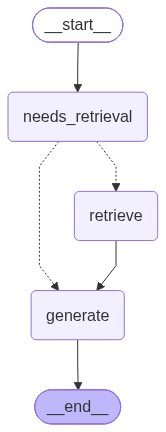

In [17]:
graph_builder = StateGraph(AgenticRAGState)
graph_builder.add_node("needs_retrieval", route_question)
graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "needs_retrieval")
graph_builder.add_conditional_edges("needs_retrieval", route_after_classification)
graph_builder.add_edge("retrieve", "generate")

graph_builder.add_edge("generate", END)
graph = graph_builder.compile()
graph

In [18]:
# Query 1: domain-specific (should trigger retrieval)
domain_query = "What does the report say about EV adoption trajectories and oil demand displacement?"

result_domain = graph.invoke({"query": domain_query, "messages": []})

In [19]:
result_domain

{'messages': [],
 'query': 'What does the report say about EV adoption trajectories and oil demand displacement?',
 'retrieved_docs': [Document(id='e02accdb-e521-48ba-be13-e3eafd492b67', metadata={}, page_content='Will EVs Dampen the Oil Price Shock?\nVersion 1.0\nResearch Report — For Educational and RAG Pipeline Use\nPage 8\n4. EV Adoption Trajectories and Oil Demand Displacement\n Projecting oil demand displacement from EV adoption requires integrating three distinct\nanalytical layers: the annual sales trajectory for new EVs, the retirement rate of the existing\nICE fleet, and the average annual mileage and fuel economy of the vehicles being displaced.\nThe total stock of passenger vehicles globally stands at approximately 1.4 billion, the vast\nmajority of which are ICE vehicles. With global new vehicle sales of roughly 90 million units\nper year and average vehicle lifetimes of 15 to 20 years in developed markets — and often\nlonger in developing markets — complete fleet electrif

In [20]:
general_query = "What is the capital of India?"
result_general = graph.invoke({"query": general_query, "messages": [], "context": None})

inside else part


In [21]:
result_general

{'messages': [],
 'query': 'What is the capital of India?',
 'context': None,
 'generation': 'The capital of India is New Delhi. \n\n(Officially, New Delhi is the seat of government within the larger National Capital Territory of Delhi.)',
 'needs_retrieval': False}

In [22]:
route_question(AgenticRAGState(query="who is prime minimiser of India"))

{'needs_retrieval': False}